In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [ ]:

from sklearn.cluster import KMeans

In [ ]:
df = pd.DataFrame({
    "SpendingScore": [1, 1, 2, 2, 3.5, 5, 5, 6, 6, 9, 9, 10, 10, 12],
    "Visits":        [1, 2, 1, 2, 1.1, 6, 7, 6, 7, 1, 2, 1, 2, 9]
})
df

# i need Customer type

,SpendingScore,Visits
0,1.0,1.0
1,1.0,2.0
2,2.0,1.0
3,2.0,2.0
4,3.5,1.1
5,5.0,6.0
6,5.0,7.0
7,6.0,6.0
8,6.0,7.0
9,9.0,1.0


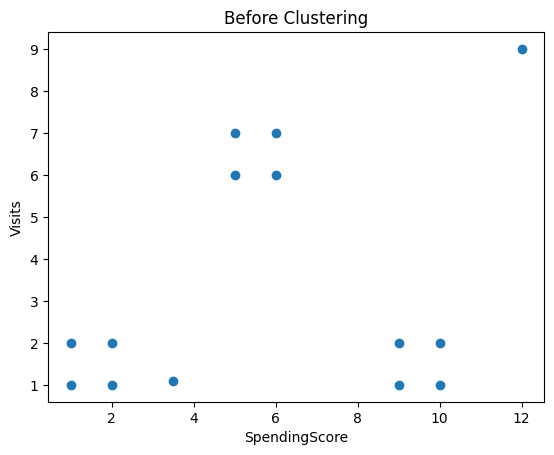

In [ ]:
plt.scatter(df["SpendingScore"], df["Visits"])
plt.xlabel("SpendingScore")
plt.ylabel("Visits")
plt.title("Before Clustering")
plt.show()

In [ ]:
# euclidean_distance For example
A = (1,1)
B = (5,6)
euclidean_distance = ((B[0]-A[0])**2   + (B[1]-A[1])**2 )**0.5
euclidean_distance

C1 = (1,1)
C2 = (5,6)
C3 = (9,1)

# new point center??
point = (2,1)

print("Distance to C1" , np.linalg.norm( np.array(point) - C1,2))
print("Distance to C2" , np.linalg.norm( np.array(point) - C2,2))
print("Distance to C3" , np.linalg.norm( np.array(point) - C3,2))

Distance to C1 1.0
Distance to C2 5.830951894845301
Distance to C3 7.0


inetria  اقل ما يمكن
بحسب المسافة بين كل نقطة والمركز تبعها
بعديها هنربع المسافة
ونجمع الها كل القيم

# فهذا يعني انو ممكن يكون هاد افضل تقسيمة


In [ ]:
# Create Kmeans

kmeans =  KMeans(
    n_clusters=3,
    random_state=0,
    n_init = 10, # inetria
    max_iter=300
)

X = df[['SpendingScore',"Visits"]]
kmeans.fit(X)

KMeans(n_clusters=3, n_init=10, random_state=0)

In [ ]:
df['cluster'] = kmeans.labels_
df

,SpendingScore,Visits,cluster
0,1.0,1.0,2
1,1.0,2.0,2
2,2.0,1.0,2
3,2.0,2.0,2
4,3.5,1.1,2
5,5.0,6.0,0
6,5.0,7.0,0
7,6.0,6.0,0
8,6.0,7.0,0
9,9.0,1.0,1


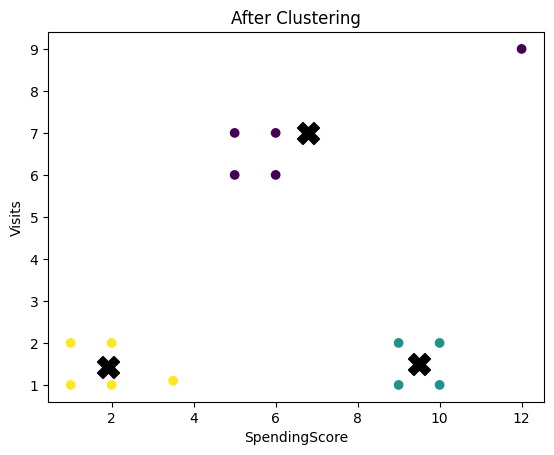

In [ ]:
plt.scatter(df['SpendingScore'],df['Visits'],c=df['cluster'],cmap ="viridis" )
plt.scatter(kmeans.cluster_centers_[:,0],kmeans.cluster_centers_[:,1],color="black",marker = "X",s =250)

plt.xlabel("SpendingScore")
plt.ylabel("Visits")
plt.title("After Clustering")
plt.show()

In [ ]:
kmeans.n_iter_

2

In [ ]:
kmeans.inertia_

48.128

# Elbow



In [ ]:
inertia = []

for k in range(1,8):
  model =  KMeans(
    n_clusters=k,
    random_state=0,
    n_init = 10, # inetria
    max_iter=300
  )
  model.fit(X)
  inertia.append(model.inertia_)

In [ ]:
inertia

[282.75571428571425, 131.5502222222222, 48.128, 9.328, 6.0, 5.0, 4.0]

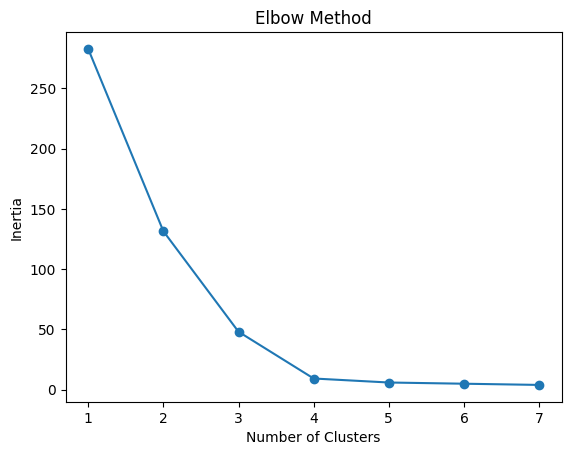

In [ ]:
plt.plot(range(1,8),inertia,marker = "o")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()


In [ ]:
df

,SpendingScore,Visits,cluster
0,1.0,1.0,2
1,1.0,2.0,2
2,2.0,1.0,2
3,2.0,2.0,2
4,3.5,1.1,2
5,5.0,6.0,0
6,5.0,7.0,0
7,6.0,6.0,0
8,6.0,7.0,0
9,9.0,1.0,1


In [ ]:
summary= df.groupby("cluster").agg(
    Customers_count = ("cluster","count"),
    Avg_SpendingScore = ("SpendingScore","mean"),
    Avg_Visits = ("Visits","mean")
)
summary

,Customers_count,Avg_SpendingScore,Avg_Visits
cluster,,,
0,5,6.8,7.00
1,4,9.5,1.50
2,5,1.9,1.42


# Break 8:00 > 8:15
# Review and run the Above Code:  8:15 > 8:30

